# Pixels

You will build: a generated plasma picture beside vector shapes, then cut, masked and tinted versions of it.

Run it from this folder with ``python pixels.py``, or open ``pixels.ipynb``.

In [1]:
import numpy as np

import svgwriter as svg

An `Image` shows a numpy array of colours (values 0 to 1). This one is a plasma pattern, turned slightly.

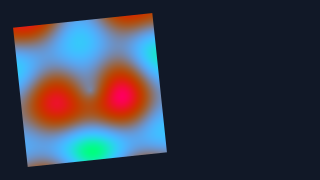

In [2]:
SIZE = 128
y, x = np.mgrid[0:SIZE, 0:SIZE] / SIZE
value = np.sin(10 * x) + np.sin(10 * y + 2) + np.sin(10 * np.hypot(x - 0.5, y - 0.5))
phase = (value - value.min()) / np.ptp(value)
pixels = np.dstack([phase, 1 - phase, 0.5 + 0.5 * np.sin(6 * phase)])

doc = svg.Document(320, 180)
doc.rect(0, 0, 320, 180, fill="#111827")
picture = svg.Image(pixels, 20, 20, 140, 140)
doc += picture.rotate(-6)
doc

`picture.alpha` sets transparency per pixel: here a soft round fade.

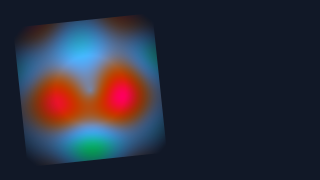

In [3]:
picture.alpha = np.clip(1.6 - 2.4 * np.hypot(x - 0.5, y - 0.5), 0, 1)
doc

Shapes sit beside the pixels, and `to_image` turns any shape into a picture you can place and scale.

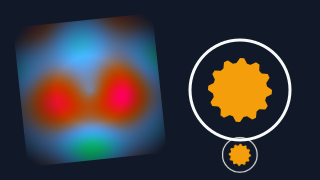

In [4]:
vector = doc.group(stroke="#f9fafb", stroke_width=3, fill="none")
vector.add(svg.circle(240, 90, 50))
vector.add(svg.paths.gear(240, 90, 32, teeth=12, fill="#f59e0b", stroke="none"))
snapshot = vector.to_image(scale=0.5)
doc += snapshot.place(240, 155) * 0.35
doc

## Combining pixels with shapes

Pixels combine with shapes using operators: `&` keeps the pixels inside a shape, `-` cuts the shape out
and `|` lays one on top of the other. Here a plasma tile is kept inside a circle, cut by a star and labelled.

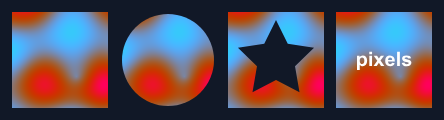

In [5]:
TILE = 96
tile = svg.Image(pixels[:TILE, :TILE], 0, 0, TILE, TILE).pixels

masked = tile & svg.circle(48, 48, 46)
cut = tile - svg.paths.star(48, 48, 40, points=5)
label = svg.text("pixels", x=48, y=54, font_size=20, font_family="Arial, Helvetica, sans-serif",
                 font_weight="bold", text_anchor="middle", fill="white")
labelled = tile.on_grid(label) | tile

board = svg.Document(4 * TILE + 5 * 12, TILE + 24)
board.rect(0, 0, 4 * TILE + 60, TILE + 24, fill="#111827")
for index, result in enumerate((tile, masked, cut, labelled)):
    board += svg.Image(result.rgba(), 12 + index * (TILE + 12), 12, TILE, TILE)
board

`composite` mixes in a colour with a blend mode: `"multiply"` tints the tile, `"screen"` lightens it.

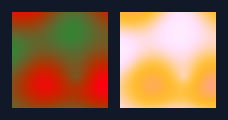

In [6]:
amber = np.array([[[1.0, 0.65, 0.2, 1.0]]])
tinted = tile.composite(amber, "multiply")
screened = tile.composite(amber, "screen")
doc2 = svg.Document(2 * TILE + 36, TILE + 24)
doc2.rect(0, 0, 2 * TILE + 36, TILE + 24, fill="#111827")
doc2 += svg.Image(tinted.rgba(), 12, 12, TILE, TILE)
doc2 += svg.Image(screened.rgba(), TILE + 24, 12, TILE, TILE)
doc2

Save them. Next: [11 Formats](../11_formats/formats.py) exports to PNG, PDF, PowerPoint and more.

In [7]:
doc.save("10_pixels.svg")
board.save("10_compositing.svg")
doc2.save("10_blend.svg")